# Credit Card Fraud Detection Using Machine Learning

**Algorithms:** Logistic Regression and Random Forest  
**Dataset:** Kaggle Credit Card Fraud Detection (`creditcard.csv`)

This notebook trains and evaluates two classifiers for identifying potentially fraudulent transactions. The dataset is highly imbalanced, so precision, recall, F1-score, PR-AUC and the confusion matrix are reported alongside accuracy.

## How to run
1. Download `creditcard.csv` from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
2. Put it in the `Dataset/` folder beside this notebook, or upload it when prompted.
3. Run all cells from top to bottom.
4. Generated model files and charts are saved in `models/` and `outputs/`.

## 1. Import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, PrecisionRecallDisplay
)

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [2]:
DATA_PATH = os.path.join("Dataset", "creditcard.csv")

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except Exception:
        raise FileNotFoundError(
            "Dataset not found. Download creditcard.csv from Kaggle and place it "
            "inside the Dataset folder, then rerun this cell."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Inspect and explore the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Class
Genuine (0)    284315
Fraud (1)         492
Name: count, dtype: int64

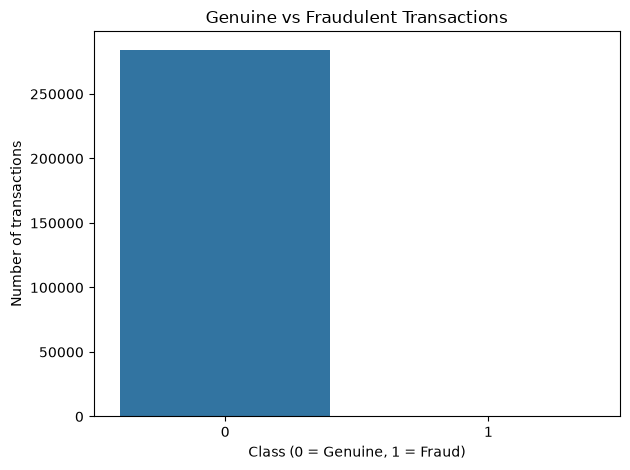

In [3]:
print(df.info())
print("\nMissing values:", int(df.isnull().sum().sum()))
print("\nClass distribution:")
display(df["Class"].value_counts().rename(index={0: "Genuine (0)", 1: "Fraud (1)"}))

ax = sns.countplot(data=df, x="Class")
ax.set_title("Genuine vs Fraudulent Transactions")
ax.set_xlabel("Class (0 = Genuine, 1 = Fraud)")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.savefig("outputs/class_distribution.png", dpi=150)
plt.show()

## 4. Prepare features and target

`Class` is the target column. We use a stratified train-test split to preserve the rare fraud proportion in both sets. Scaling is fitted only on the training data to avoid data leakage.

In [4]:
if "Class" not in df.columns:
    raise ValueError("The dataset must contain a 'Class' target column.")

X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
scale_columns = [c for c in ["Time", "Amount"] if c in X_train.columns]

X_train = X_train.copy()
X_test = X_test.copy()
if scale_columns:
    X_train.loc[:, scale_columns] = scaler.fit_transform(X_train[scale_columns])
    X_test.loc[:, scale_columns] = scaler.transform(X_test[scale_columns])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Fraud cases in test set:", int(y_test.sum()))

Training rows: 227845
Testing rows: 56962
Fraud cases in test set: 98


## 5. Train Logistic Regression

In [5]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE
)
logistic_model.fit(X_train, y_train)
lr_predictions = logistic_model.predict(X_test)
lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]
print("Logistic Regression training complete.")

Logistic Regression training complete.


## 6. Train Random Forest

In [6]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]
print("Random Forest training complete.")

Random Forest training complete.


## 7. Evaluate and compare models

In [7]:
def calculate_metrics(name, y_true, predictions, probabilities):
    return {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }

results = pd.DataFrame([
    calculate_metrics("Logistic Regression", y_test, lr_predictions, lr_probabilities),
    calculate_metrics("Random Forest", y_test, rf_predictions, rf_probabilities)
])
display(results.round(4))
results.to_csv("outputs/model_comparison.csv", index=False)

print("Logistic Regression report:")
print(classification_report(y_test, lr_predictions, zero_division=0))
print("Random Forest report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

,Algorithm,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9755,0.061,0.9184,0.1144,0.9722,0.7159
1,Random Forest,0.9995,0.960,0.7347,0.8324,0.9529,0.8597


Logistic Regression report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Random Forest report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.73      0.83        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



## 8. Confusion matrices

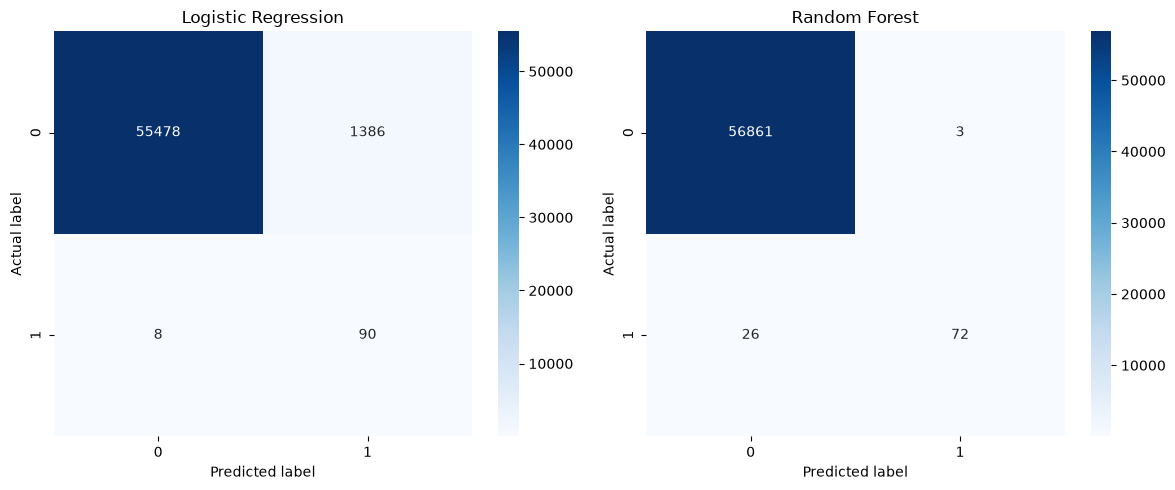

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, predictions in [
    (axes[0], "Logistic Regression", lr_predictions),
    (axes[1], "Random Forest", rf_predictions)
]:
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.savefig("outputs/confusion_matrices.png", dpi=150)
plt.show()

## 9. Precision-recall curves

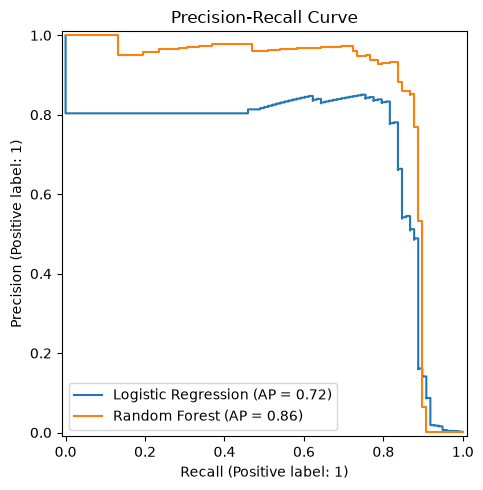

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, lr_probabilities, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, rf_probabilities, name="Random Forest", ax=ax)
ax.set_title("Precision-Recall Curve")
plt.tight_layout()
plt.savefig("outputs/precision_recall_curve.png", dpi=150)
plt.show()

## 10. Save the trained models and preprocessing object

In [10]:
joblib.dump(logistic_model, "models/logistic_regression_model.pkl")
joblib.dump(random_forest_model, "models/random_forest_model.pkl")
joblib.dump(scaler, "models/standard_scaler.pkl")
joblib.dump(list(X.columns), "models/feature_columns.pkl")

print("Models and preprocessing files saved in the models/ folder.")

Models and preprocessing files saved in the models/ folder.


## 11. Demonstrate a prediction

This example predicts one held-out test transaction. It is not a manually invented transaction.

In [11]:
sample = X_test.iloc[[0]]
predicted_class = int(random_forest_model.predict(sample)[0])
fraud_probability = float(random_forest_model.predict_proba(sample)[0, 1])

print("Prediction:", "Fraudulent" if predicted_class == 1 else "Genuine")
print(f"Estimated fraud probability: {fraud_probability:.2%}")

Prediction: Genuine
Estimated fraud probability: 0.00%


## 12. Conclusion

The notebook trained Logistic Regression and Random Forest models and compared them using metrics suited to an imbalanced classification problem. Review the measured results above before deciding which model is preferable. This is an educational prototype, not a production banking fraud system.

## References

- Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Scikit-learn documentation: https://scikit-learn.org/stable/